Can we see the weather event in the weather data? 

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from dotenv import dotenv_values
from sqlalchemy import create_engine

config = dotenv_values()
db_url = (f"postgresql://{config['POSTGRES_USER']}:{config['POSTGRES_PASS']}"
          f"@{config['POSTGRES_HOST']}:{config['POSTGRES_PORT']}/{config['POSTGRES_DB']}")
engine = create_engine(db_url)

SCHEMA = 'team_a'

In [11]:
flights = pd.read_sql(f'SELECT * FROM {SCHEMA}.prep_flights', engine)
weather = pd.read_sql(f'SELECT * FROM {SCHEMA}.prep_weather_hourly', engine)
airports = pd.read_sql(f'SELECT * FROM {SCHEMA}.prep_airports', engine)

display(flights.head())
display(weather.head())
display(airports.head())

,flight_date,dep_time,sched_dep_time,dep_delay,dep_delay_interval,arr_time,sched_arr_time,arr_delay,arr_delay_interval,airline,...,flight_number,origin,dest,air_time,air_time_interval,actual_elapsed_time,actual_elapsed_time_interval,distance_km,cancelled,diverted
0,2021-01-01,00:38:00,00:30:00,8.0,0 days 00:08:00,05:46:00,05:38:00,8.0,0 days 00:08:00,UA,...,2181,LAX,IAH,168.0,0 days 02:48:00,188.0,0 days 03:08:00,2219.29,0,0
1,2021-01-01,01:36:00,01:01:00,35.0,0 days 00:35:00,06:07:00,05:37:00,30.0,0 days 00:30:00,NK,...,934,LAS,DFW,132.0,0 days 02:12:00,151.0,0 days 02:31:00,1697.86,0,0
2,2021-01-01,02:30:00,02:29:00,1.0,0 days 00:01:00,05:36:00,05:41:00,-5.0,-1 days +23:55:00,NK,...,972,PHX,DFW,111.0,0 days 01:51:00,126.0,0 days 02:06:00,1396.91,0,0
3,2021-01-01,04:59:00,05:00:00,-1.0,-1 days +23:59:00,09:46:00,09:44:00,2.0,0 days 00:02:00,AA,...,187,LAS,DFW,139.0,0 days 02:19:00,167.0,0 days 02:47:00,1697.86,0,0
4,2021-01-01,05:24:00,05:25:00,-1.0,-1 days +23:59:00,08:44:00,08:48:00,-4.0,-1 days +23:56:00,UA,...,1415,DEN,IAH,122.0,0 days 02:02:00,140.0,0 days 02:20:00,1387.25,0,0


,airport_code,station_id,timestamp,temp_c,dewpoint_c,humidity_perc,precipitation_mm,snow_mm,wind_direction,wind_speed_kmh,...,time,hour,month_name,weekday,date_day,date_month,date_year,cw,day_part,condition_name
0,AUS,72254,2021-01-01 00:00:00,2.8,0.0,82.0,NaN,None,260,11.2,...,00:00:00,00:00,january,friday,1.0,1.0,2021.0,53.0,night,Overcast
1,AUS,72254,2021-01-01 01:00:00,2.8,-0.7,78.0,0.0,None,279,13.0,...,01:00:00,01:00,january,friday,1.0,1.0,2021.0,53.0,night,Overcast
2,AUS,72254,2021-01-01 02:00:00,2.8,-1.0,76.0,0.0,None,284,11.2,...,02:00:00,02:00,january,friday,1.0,1.0,2021.0,53.0,night,Overcast
3,AUS,72254,2021-01-01 03:00:00,2.8,-1.0,76.0,0.0,None,272,9.4,...,03:00:00,03:00,january,friday,1.0,1.0,2021.0,53.0,night,Overcast
4,AUS,72254,2021-01-01 04:00:00,2.8,-1.0,76.0,0.0,None,283,7.6,...,04:00:00,04:00,january,friday,1.0,1.0,2021.0,53.0,night,Overcast


,faa,name,city,country,lat,lon,alt,tz,dst
0,GKA,Goroka Airport,Goroka,Papua New Guinea,-6.081690,145.391998,5282,10.0,U
1,MAG,Madang Airport,Madang,Papua New Guinea,-5.207080,145.789001,20,10.0,U
2,HGU,Mount Hagen Kagamuga Airport,Mount Hagen,Papua New Guinea,-5.826790,144.296005,5388,10.0,U
3,LAE,Nadzab Airport,Nadzab,Papua New Guinea,-6.569803,146.725977,239,10.0,U
4,POM,Port Moresby Jacksons International Airport,Port Moresby,Papua New Guinea,-9.443380,147.220001,146,10.0,U


In [12]:
# checking the weather columns

print(weather.columns.tolist())

['airport_code', 'station_id', 'timestamp', 'temp_c', 'dewpoint_c', 'humidity_perc', 'precipitation_mm', 'snow_mm', 'wind_direction', 'wind_speed_kmh', 'wind_peakgust_kmh', 'pressure_hpa', 'sun_minutes', 'condition_code', 'date', 'time', 'hour', 'month_name', 'weekday', 'date_day', 'date_month', 'date_year', 'cw', 'day_part', 'condition_name']


In [13]:
flights['flight_date'] = pd.to_datetime(flights['flight_date'])
weather['date'] = pd.to_datetime(weather['date'])

flights['sched_dep_hour'] = pd.to_datetime(
    flights['flight_date'].dt.strftime('%Y-%m-%d') + ' ' + flights['sched_dep_time'].astype(str)
).dt.floor('h')

flights[['flight_date', 'sched_dep_time', 'sched_dep_hour']].head()

,flight_date,sched_dep_time,sched_dep_hour
0,2021-01-01,00:30:00,2021-01-01 00:00:00
1,2021-01-01,01:01:00,2021-01-01 01:00:00
2,2021-01-01,02:29:00,2021-01-01 02:00:00
3,2021-01-01,05:00:00,2021-01-01 05:00:00
4,2021-01-01,05:25:00,2021-01-01 05:00:00


In [14]:
flights_weather = flights.merge(
    weather,
    left_on=['origin', 'sched_dep_hour'],
    right_on=['airport_code', 'timestamp'],
    how='left'
)

flights_weather

,flight_date,dep_time,sched_dep_time,dep_delay,dep_delay_interval,arr_time,sched_arr_time,arr_delay,arr_delay_interval,airline,...,time,hour,month_name,weekday,date_day,date_month,date_year,cw,day_part,condition_name
0,2021-01-01,00:38:00,00:30:00,8.0,0 days 00:08:00,05:46:00,05:38:00,8.0,0 days 00:08:00,UA,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2021-01-01,01:36:00,01:01:00,35.0,0 days 00:35:00,06:07:00,05:37:00,30.0,0 days 00:30:00,NK,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2021-01-01,02:30:00,02:29:00,1.0,0 days 00:01:00,05:36:00,05:41:00,-5.0,-1 days +23:55:00,NK,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2021-01-01,04:59:00,05:00:00,-1.0,-1 days +23:59:00,09:46:00,09:44:00,2.0,0 days 00:02:00,AA,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2021-01-01,05:24:00,05:25:00,-1.0,-1 days +23:59:00,08:44:00,08:48:00,-4.0,-1 days +23:56:00,UA,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
116143,2021-02-28,21:29:00,21:35:00,-6.0,-1 days +23:54:00,23:39:00,23:59:00,-20.0,-1 days +23:40:00,AA,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
116144,2021-02-28,21:38:00,21:40:00,-2.0,-1 days +23:58:00,23:01:00,23:09:00,-8.0,-1 days +23:52:00,DL,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
116145,2021-02-28,21:59:00,21:59:00,0.0,0 days 00:00:00,00:50:00,00:47:00,3.0,0 days 00:03:00,NK,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
116146,2021-02-28,22:27:00,22:30:00,-3.0,-1 days +23:57:00,23:56:00,23:49:00,7.0,0 days 00:07:00,DL,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [15]:
AIRPORTS = ['DFW', 'IAH', 'AUS', 'SAT']

# group weather conditions (all conditions present in the data)
CONDITION_GROUPS = {
    'Freezing Rain': 'ice', 'Heavy Freezing Rain': 'ice', 'Sleet': 'ice',
    'Light Snowfall': 'snow', 'Snowfall': 'snow', 'Heavy Snowfall': 'snow',
    'Light Rain': 'rain', 'Rain': 'rain', 'Heavy Rain': 'rain',
    'Rain Shower': 'rain', 'Heavy Rain Shower': 'rain',
    'Thunderstorm': 'rain', 'Heavy Thunderstorm': 'rain', 'Hail': 'rain',
    'Fog': 'fog',
    # Fair, Clear, Cloudy, Overcast -> 'dry'
}

def add_weather_group(df):
    df['weather_group'] = np.where(
        df['condition_name'].isna(), 'no data',
        df['condition_name'].map(CONDITION_GROUPS).fillna('dry'))
    df['winter_precip'] = df['weather_group'].isin(['ice', 'snow'])
    return df

def add_period(df, date_col='flight_date'):
    df['period'] = np.select(
        [df[date_col] < '2021-02-14', df[date_col] <= '2021-02-19'],
        ['1_before', '2_storm'], '3_after')
    return df

weather = add_weather_group(weather)

# departures from our airports, with weather at the scheduled departure hour
dep = add_period(add_weather_group(
    flights_weather[flights_weather['origin'].isin(AIRPORTS)].copy()))

# arrivals to our airports (for diversions)
arr = add_period(flights[flights['dest'].isin(AIRPORTS)].copy())

print(weather['weather_group'].value_counts())
print(dep['weather_group'].value_counts())

weather_group
dry     4573
rain     495
fog      394
ice      116
snow      86
Name: count, dtype: int64
weather_group
dry     49575
rain     5237
fog      3339
snow     1171
ice       666
Name: count, dtype: int64


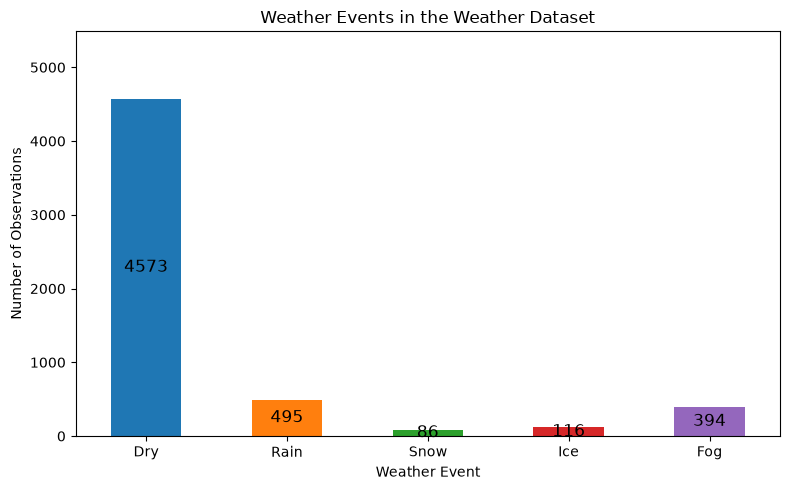

In [16]:
event_counts = weather.loc[
    weather["weather_group"].isin(["dry", "ice", "snow", "rain", "fog"]),
    "weather_group"
].value_counts()

event_counts = event_counts.reindex(
    ["dry", "rain", "snow", "ice", "fog"]
).dropna()

# Rename for display
event_counts.index = ["Dry", "Rain", "Snow", "Ice", "Fog"]

# Same colors as the other weather visualizations
weather_colors = [
    "#1f77b4",  # Dry - blue
    "#ff7f0e",  # Rain - orange
    "#2ca02c",  # Snow - green
    "#d62728",  # Ice - red
    "#9467bd"   # Fog - purple
]

ax = event_counts.plot(
    kind="bar",
    figsize=(8, 5),
    color=weather_colors
)

plt.title("Weather Events in the Weather Dataset")
plt.xlabel("Weather Event")
plt.ylabel("Number of Observations")
plt.xticks(rotation=0)

plt.ylim(0, max(event_counts) * 1.2)

for i, value in enumerate(event_counts):
    ax.text(
        i,
        value / 2,
        str(int(value)),
        ha="center",
        va="center",
        fontsize=12
    )

plt.tight_layout()
plt.show()

**Weather events can be identified directly in the weather data. We grouped the recorded weather conditions into five main categories: Dry, Rain, Snow, Ice, and Fog. The bar chart shows the number of observations for each event, confirming that different weather events are present in the dataset.**


In [17]:
weather["date"] = pd.to_datetime(weather["date"])

weather = add_period(
    weather,
    date_col="date"
)

print(weather.columns.tolist())

['airport_code', 'station_id', 'timestamp', 'temp_c', 'dewpoint_c', 'humidity_perc', 'precipitation_mm', 'snow_mm', 'wind_direction', 'wind_speed_kmh', 'wind_peakgust_kmh', 'pressure_hpa', 'sun_minutes', 'condition_code', 'date', 'time', 'hour', 'month_name', 'weekday', 'date_day', 'date_month', 'date_year', 'cw', 'day_part', 'condition_name', 'weather_group', 'winter_precip', 'period']


In [18]:
# Weather conditions as percentages within each period
period_weather = pd.crosstab(
    weather["period"],
    weather["weather_group"],
    normalize="index"
) * 100

# Keep the weather categories in the desired order
period_weather = period_weather.reindex(
    columns=["dry", "rain", "snow", "ice", "fog"],
    fill_value=0
)

# Display percentages
display(period_weather.round(1))

weather_group,dry,rain,snow,ice,fog
period,,,,,
1_before,83.1,8.9,0.2,0.9,6.9
2_storm,62.0,5.7,13.7,13.4,5.2
3_after,81.5,10.2,0.0,0.0,8.3


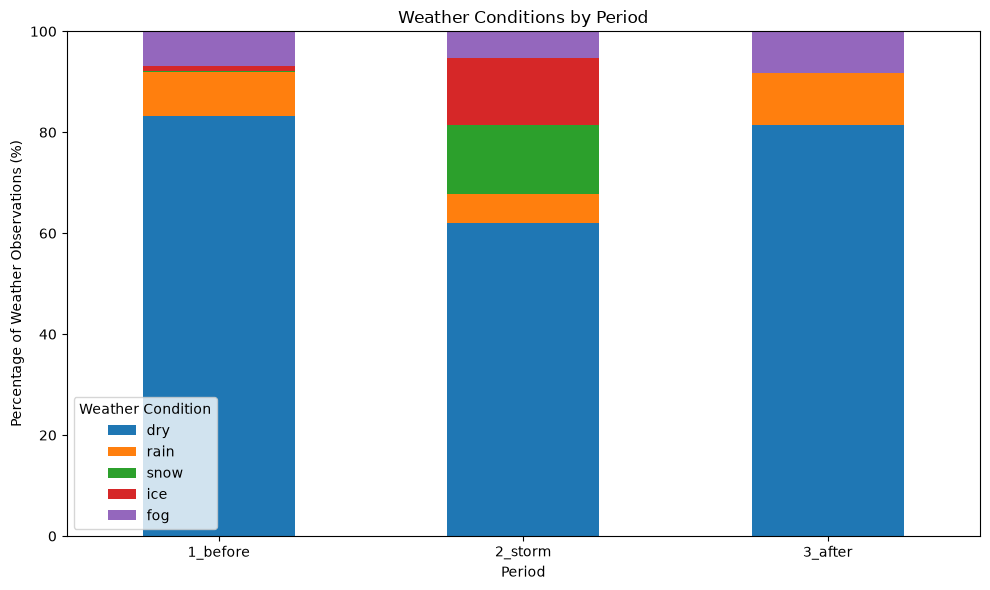

In [19]:
period_weather.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Weather Conditions by Period")
plt.xlabel("Period")
plt.ylabel("Percentage of Weather Observations (%)")
plt.xticks(rotation=0)
plt.legend(title="Weather Condition")

plt.ylim(0, 100)

plt.tight_layout()
plt.show()

In [20]:
# Weather conditions as percentages within each airport
airport_weather = pd.crosstab(
    weather["airport_code"],
    weather["weather_group"],
    normalize="index"
) * 100

airport_weather = airport_weather.reindex(
    columns=["dry", "rain", "snow", "ice", "fog"],
    fill_value=0
)

display(airport_weather.round(1))

weather_group,dry,rain,snow,ice,fog
airport_code,,,,,
AUS,80.4,6.2,1.5,2.3,9.5
DFW,83.6,6.3,2.8,1.6,5.8
IAH,78.6,10.2,0.9,0.6,9.7
SAT,80.3,12.2,0.9,3.7,2.8


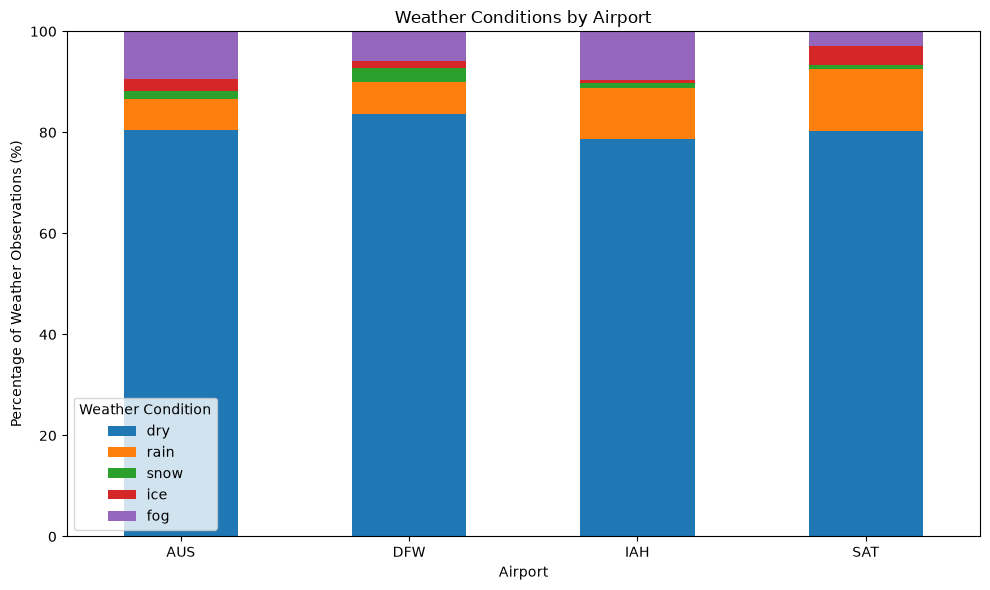

In [21]:
airport_weather.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Weather Conditions by Airport")
plt.xlabel("Airport")
plt.ylabel("Percentage of Weather Observations (%)")
plt.xticks(rotation=0)
plt.legend(title="Weather Condition")

plt.ylim(0, 100)

plt.tight_layout()
plt.show()

**Among the four airports, SAT had the highest proportion of snow and ice observations (4.6%), followed by DFW (4.4%), AUS (3.8%), and IAH (1.5%). This suggests that SAT and DFW experienced winter precipitation more frequently in the observed weather data, although the percentages alone do not measure weather intensity.**

In [22]:
# Count weather observations by timestamp and weather group
weather_time = (
    weather[
        weather["airport_code"].isin(AIRPORTS)
    ]
    .groupby(["timestamp", "weather_group"])
    .size()
    .unstack(fill_value=0)
)

# Make sure all weather categories are present
weather_time = weather_time.reindex(
    columns=["dry", "rain", "snow", "ice", "fog"],
    fill_value=0
)

# Convert counts to percentages for each timestamp
weather_time_pct = (
    weather_time
    .div(weather_time.sum(axis=1), axis=0)
    * 100
)

display(weather_time_pct.head())

weather_group,dry,rain,snow,ice,fog
timestamp,,,,,
2021-01-01 00:00:00,75.0,25.0,0.0,0.0,0.0
2021-01-01 01:00:00,75.0,25.0,0.0,0.0,0.0
2021-01-01 02:00:00,75.0,25.0,0.0,0.0,0.0
2021-01-01 03:00:00,75.0,0.0,0.0,0.0,25.0
2021-01-01 04:00:00,100.0,0.0,0.0,0.0,0.0


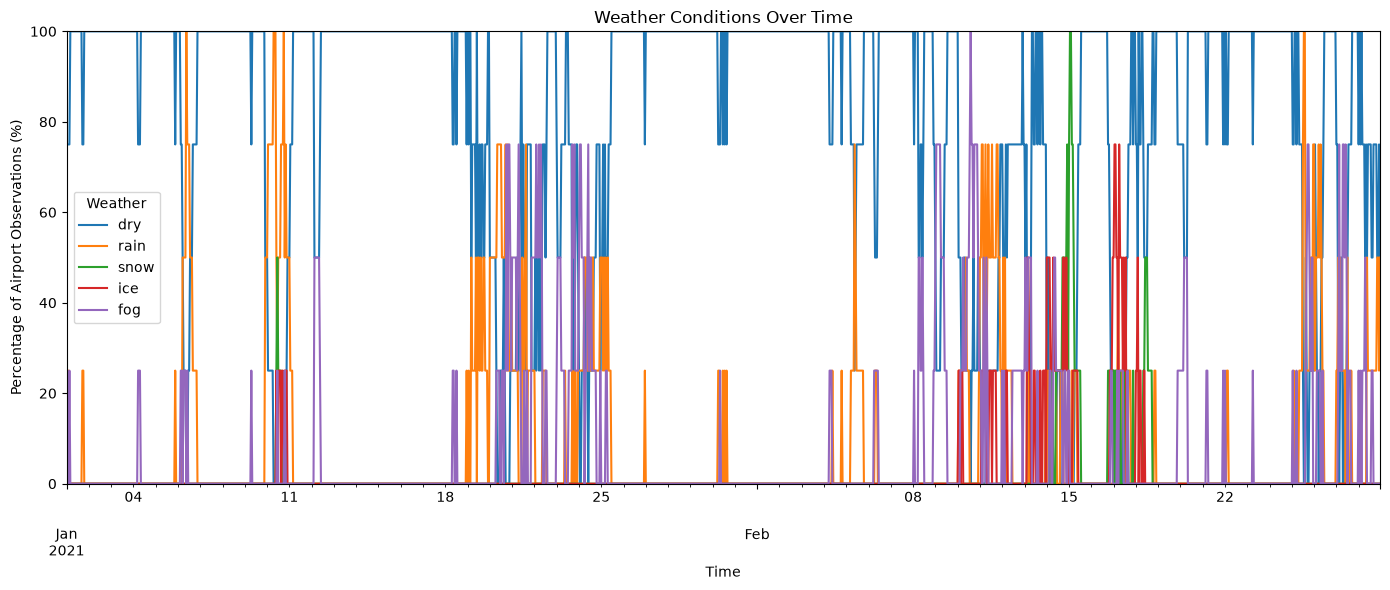

In [23]:
weather_time_pct.plot(
    figsize=(14, 6),
    color={
        "dry": "#1f77b4",
        "rain": "#ff7f0e",
        "snow": "#2ca02c",
        "ice": "#d62728",
        "fog": "#9467bd"
    }
)

plt.title("Weather Conditions Over Time")
plt.xlabel("Time")
plt.ylabel("Percentage of Airport Observations (%)")

plt.ylim(0, 100)

plt.legend(title="Weather")
plt.tight_layout()
plt.show()

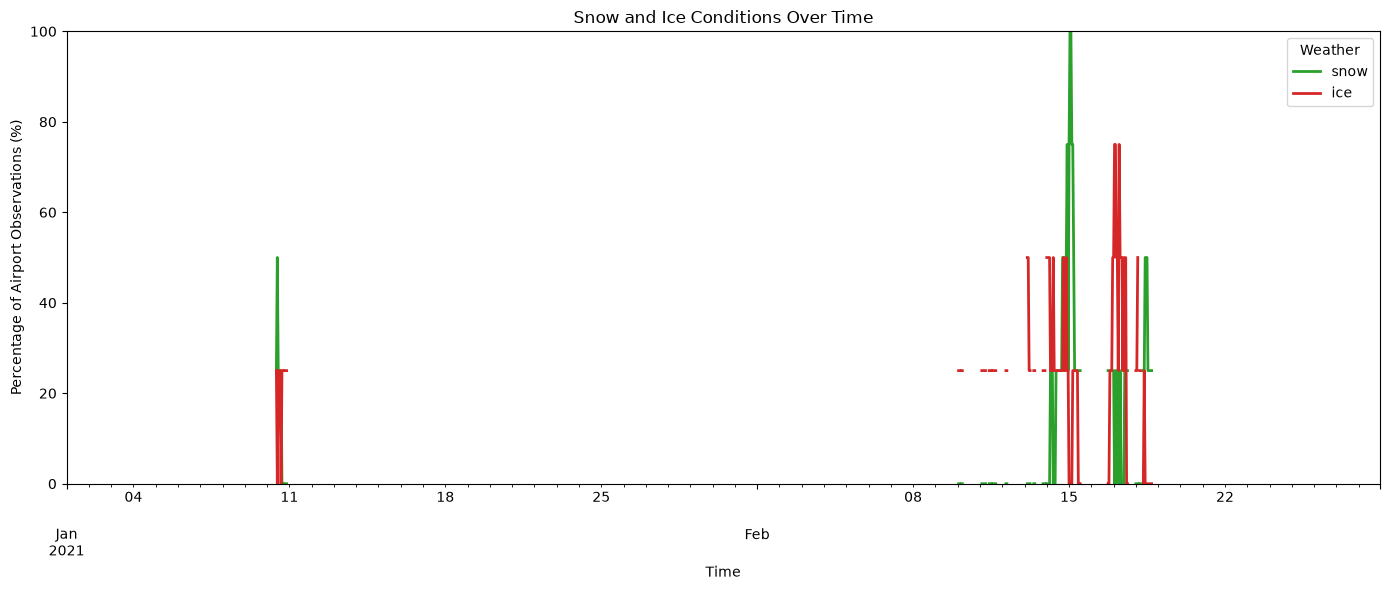

In [24]:
winter_time = (
    weather[
        (weather["airport_code"].isin(AIRPORTS)) &
        (weather["weather_group"].isin(["snow", "ice"]))
    ]
    .groupby(["timestamp", "weather_group"])
    .size()
    .unstack(fill_value=0)
)

winter_time = winter_time.reindex(
    columns=["snow", "ice"],
    fill_value=0
)

winter_time_pct = (
    winter_time
    .div(
        weather[
            weather["airport_code"].isin(AIRPORTS)
        ]
        .groupby("timestamp")
        .size(),
        axis=0
    )
    * 100
)

winter_time_pct.plot(
    figsize=(14, 6),
    color={
        "snow": "#2ca02c",
        "ice": "#d62728"
    },
    linewidth=2
)

plt.title("Snow and Ice Conditions Over Time")
plt.xlabel("Time")
plt.ylabel("Percentage of Airport Observations (%)")
plt.ylim(0, 100)

plt.legend(title="Weather")
plt.tight_layout()
plt.show()

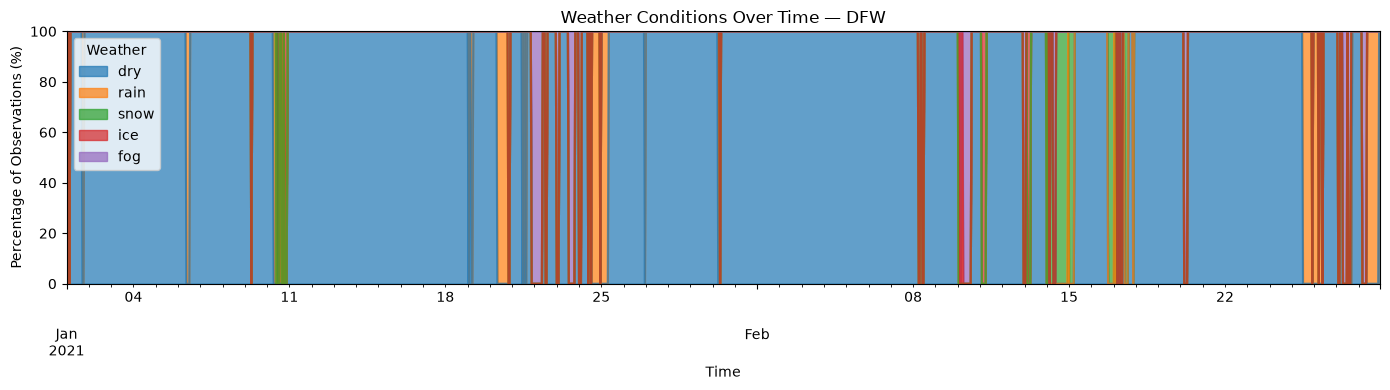

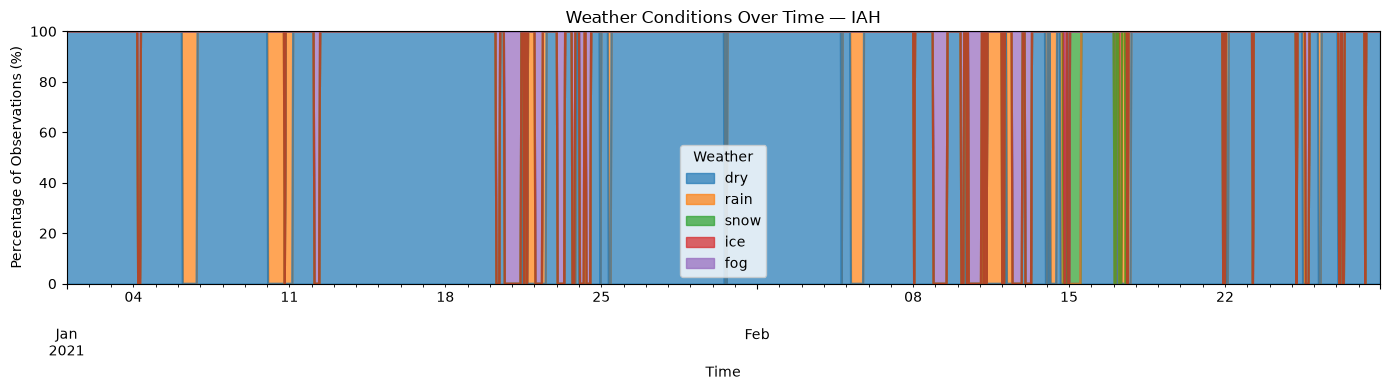

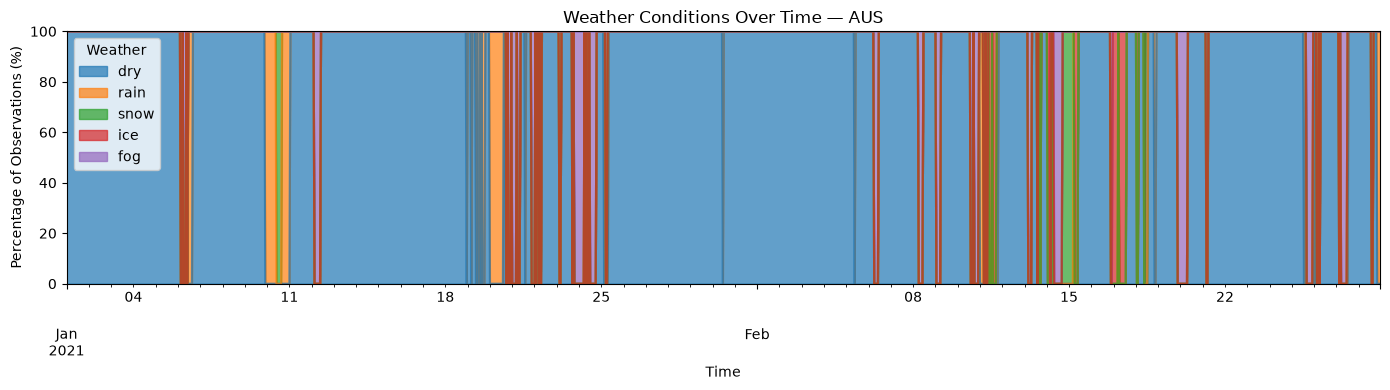

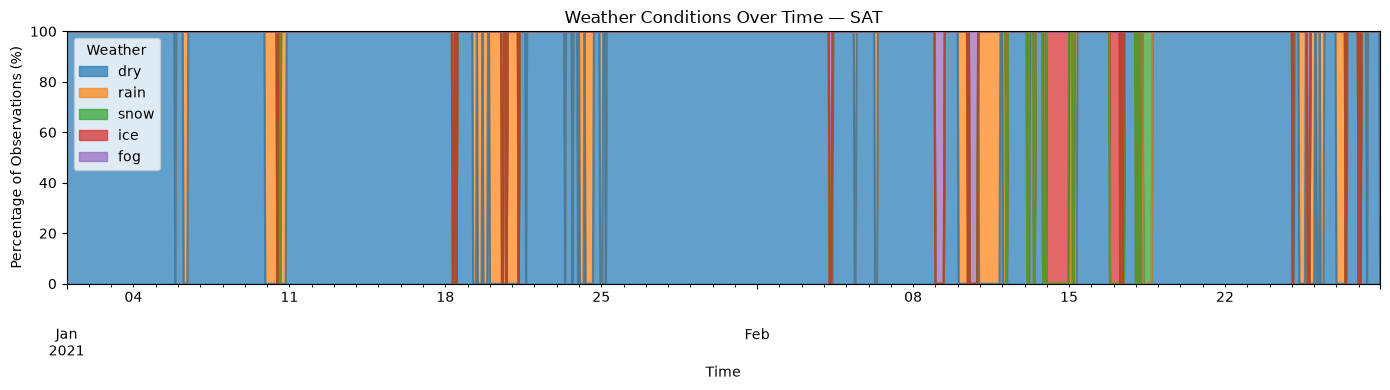

In [25]:
WEATHER_COLORS = {
    "dry": "#1f77b4",
    "rain": "#ff7f0e",
    "snow": "#2ca02c",
    "ice": "#d62728",
    "fog": "#9467bd"
}

for airport in AIRPORTS:
    
    temp = weather[
        weather["airport_code"] == airport
    ]

    counts = (
        temp.groupby(["timestamp", "weather_group"])
        .size()
        .unstack(fill_value=0)
    )

    # Make sure all weather categories are present
    counts = counts.reindex(
        columns=["dry", "rain", "snow", "ice", "fog"],
        fill_value=0
    )

    # Since this is one airport, convert each timestamp
    # into a percentage of the available observation
    counts_pct = (
        counts.div(counts.sum(axis=1), axis=0) * 100
    )

    ax = counts_pct.plot(
        figsize=(14, 4),
        kind="area",
        stacked=True,
        color=WEATHER_COLORS,
        alpha=0.7
    )

    plt.title(f"Weather Conditions Over Time — {airport}")
    plt.xlabel("Time")
    plt.ylabel("Percentage of Observations (%)")
    plt.ylim(0, 100)
    plt.legend(title="Weather")
    plt.tight_layout()
    plt.show()

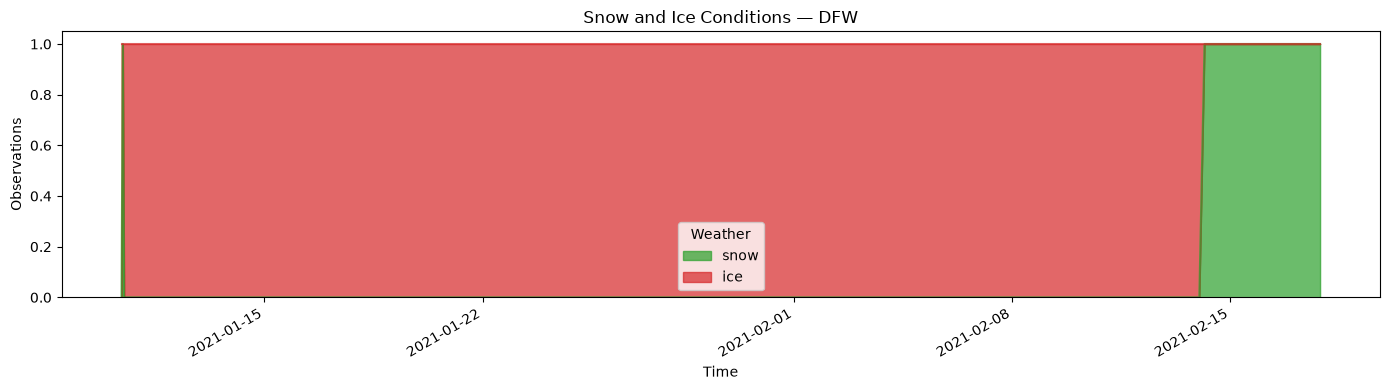

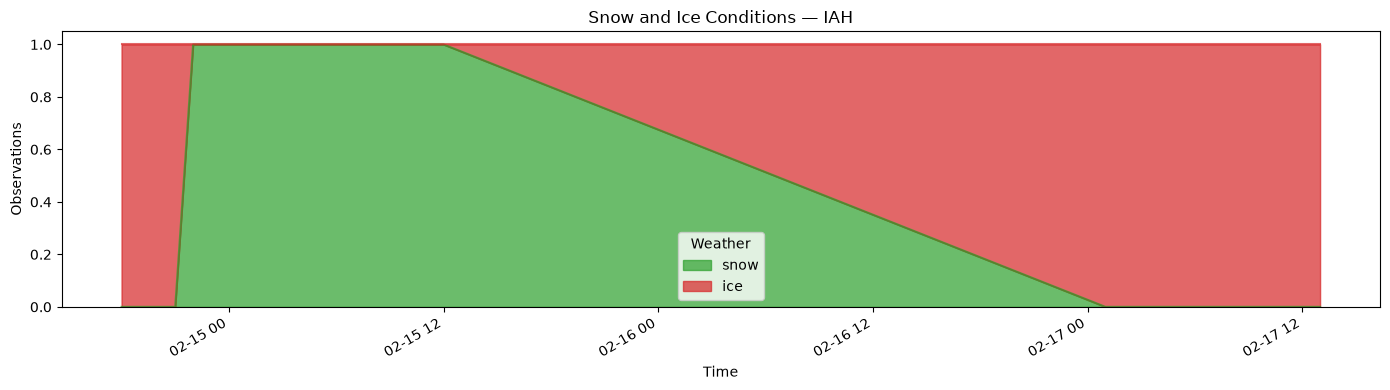

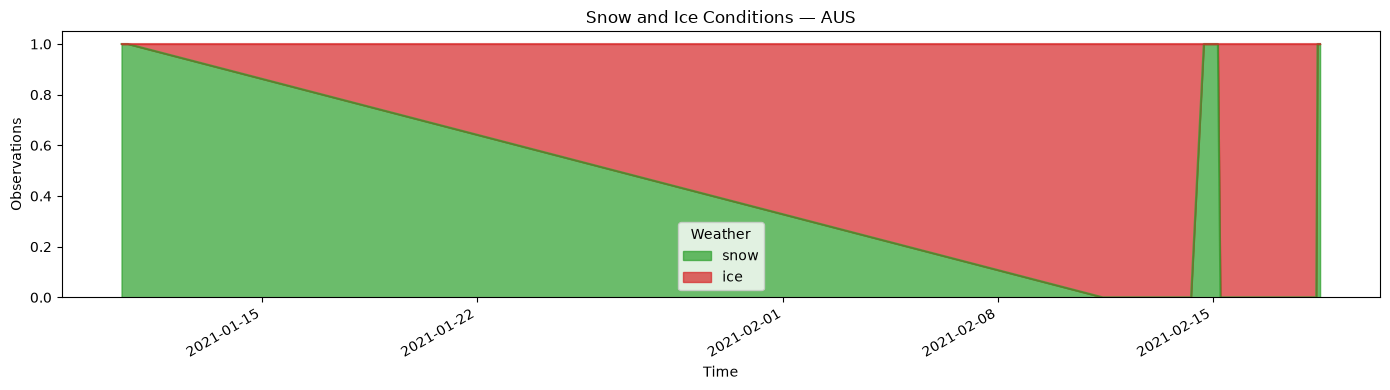

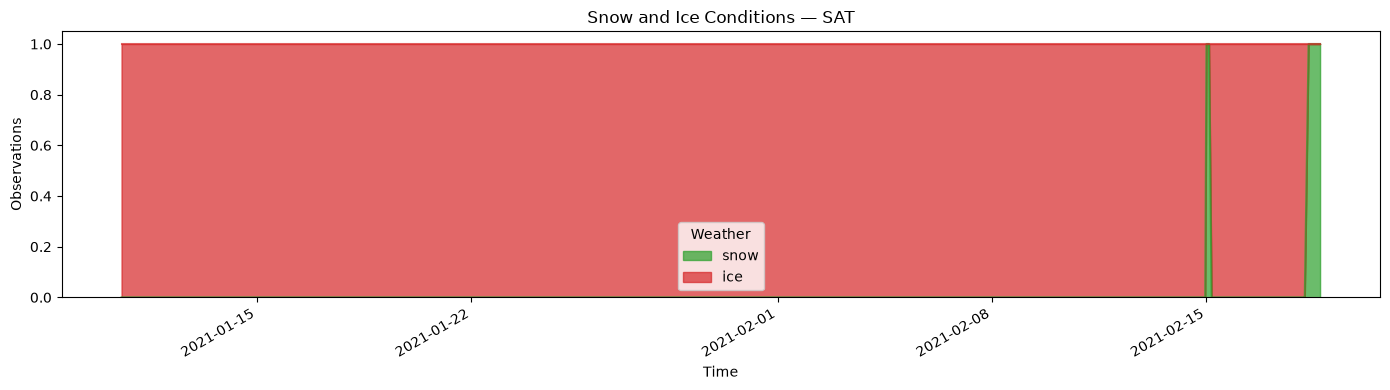

In [26]:
for airport in AIRPORTS:

    temp = weather[
        (weather["airport_code"] == airport) &
        (weather["weather_group"].isin(["snow", "ice"]))
    ]

    counts = (
        temp.groupby(["timestamp", "weather_group"])
        .size()
        .unstack(fill_value=0)
    )

    counts = counts.reindex(
        columns=["snow", "ice"],
        fill_value=0
    )

    counts.plot(
        figsize=(14, 4),
        kind="area",
        stacked=True,
        color={
            "snow": "#2ca02c",
            "ice": "#d62728"
        },
        alpha=0.7
    )

    plt.title(f"Snow and Ice Conditions — {airport}")
    plt.xlabel("Time")
    plt.ylabel("Observations")
    plt.legend(title="Weather")
    plt.tight_layout()
    plt.show()

Can we see the weather event in the flights data? 


# Winter Storm Uri: Weather vs. Flights 

**Main research question:**  
### Can we see the weather event in the flight data?

**Focus:** Winter Storm Uri, Texas, February 2021  
**Airports:** DFW, IAH, AUS, SAT  
**Study period:** February 8–22, 2021

The analysis stays focused on whether the weather event is visible through changes in flight operations.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from dotenv import dotenv_values
from sqlalchemy import create_engine

config = dotenv_values()

db_url = (
    f"postgresql://{config['POSTGRES_USER']}:{config['POSTGRES_PASS']}"
    f"@{config['POSTGRES_HOST']}:{config['POSTGRES_PORT']}/{config['POSTGRES_DB']}"
)

engine = create_engine(db_url)
SCHEMA = "team_a"

flights = pd.read_sql(f"SELECT * FROM {SCHEMA}.prep_flights", engine)
weather = pd.read_sql(f"SELECT * FROM {SCHEMA}.prep_weather_hourly", engine)

flights["flight_date"] = pd.to_datetime(flights["flight_date"])
weather["date"] = pd.to_datetime(weather["date"])

print("Flights:", flights.shape)
print("Weather:", weather.shape)

Flights: (116148, 21)
Weather: (5664, 25)


In [ ]:
# Create the scheduled departure hour so flights can be matched to hourly weather

flights["sched_dep_hour"] = pd.to_datetime(
    flights["flight_date"].dt.strftime("%Y-%m-%d")
    + " "
    + flights["sched_dep_time"].astype(str)
).dt.floor("h")

flights_weather = flights.merge(
    weather,
    left_on=["origin", "sched_dep_hour"],
    right_on=["airport_code", "timestamp"],
    how="left"
)

AIRPORTS = ["DFW", "IAH", "AUS", "SAT"]

dep = flights_weather[
    flights_weather["origin"].isin(AIRPORTS)
].copy()

print("Flights from study airports:", len(dep))

In [ ]:
## Hypotheses

### H1 — Flight cancellations increase during the storm.
If Winter Storm Uri is visible in the flight data, cancellation rates should rise sharply during February 14–19 compared with the days immediately before and after.

### H2 — Snow and ice are associated with more cancellations.
Flights scheduled during snow, freezing rain or sleet should have higher cancellation rates than flights during dry, rain or fog conditions.

### H3 — Departure delays increase during the storm.
If the storm disrupted airport operations, the average departure delay should increase during the storm period.

### H4 — The impact differs across the four airports.
The storm should be visible at DFW, IAH, AUS and SAT, but the timing and size of the disruption may differ by airport.

In [ ]:
daily_ops = (
    dep.groupby("flight_date")
    .agg(
        cancellation_rate=("cancelled", "mean"),
        average_departure_delay=("dep_delay", "mean"),
        departed=("cancelled", lambda x: (x == 0).sum())
    )
)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

daily_ops.loc["2021-02-08":"2021-02-22", "cancellation_rate"].plot(
    ax=ax1, marker="o"
)
ax1.yaxis.set_major_formatter(PercentFormatter(1.0))
ax1.set_ylabel("Cancellation rate")
ax1.set_title("Storm disruption: cancellations and departure delays")

daily_ops.loc["2021-02-08":"2021-02-22", "average_departure_delay"].plot(
    ax=ax2, marker="o"
)
ax2.set_ylabel("Average departure delay (min)")
ax2.set_xlabel("Date")

for ax in (ax1, ax2):
    ax.axvspan(
        pd.Timestamp("2021-02-14"),
        pd.Timestamp("2021-02-19"),
        alpha=0.15
    )

plt.tight_layout()
plt.show()

In [ ]:
h3 = (
    dep.groupby("period")
    .agg(
        average_departure_delay=("dep_delay", "mean"),
        cancellation_rate=("cancelled", "mean"),
        departed=("cancelled", lambda x: (x == 0).sum())
    )
)

h3["cancellation_rate"] = h3["cancellation_rate"] * 100
h3.round(1)

# Final answer

### Can we see the weather event in the flight data?

**Yes.**

The flight data shows a strong operational disruption during Winter Storm Uri. The clearest signals are:

1. **Cancellations increased sharply during the storm period.**
2. **Snow and ice conditions are associated with higher cancellation rates.**
3. **Departure delays increased during the storm.**

### Presentation takeaway

> **Winter Storm Uri is clearly visible in the flight data through increased cancellations, longer departure delays and airport-level disruption, with the strongest impact occurring around February 14–17, 2021.**

**Important:** This analysis shows that the flight disruption **coincides with** the weather event. It does not by itself prove that weather was the only cause of every cancellation or delay.

Can we see a correlation between the data? 

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

pivot = cancelled_by_weather.pivot(index='condition_name', columns='date_month', values='cancellation_count').fillna(0)
pivot.columns = ['January', 'February']
pivot = pivot.sort_values('February', ascending=False)

x = np.arange(len(pivot))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))
fig.patch.set_facecolor(BG)
ax.bar(x - width/2, pivot['January'], width, label='January 2021', color=BLUE)
ax.bar(x + width/2, pivot['February'], width, label='February 2021', color=TEAL)

ax.set_xlabel('Weather Condition')
ax.set_ylabel('Number of Cancellations')
ax.set_title('Flight Cancellations by Weather Condition — Jan vs Feb 2021')
ax.set_xticks(x)
ax.set_xticklabels(pivot.index, rotation=45, ha='right')
ax.legend()
style(ax)

plt.tight_layout()
save(fig, 'cancellations_by_condition')
plt.show()

### Chart 1: Cancellations by Weather Condition

#### Motivation: Texas winter storm Feb 2021 — how do weather conditions and cancellations relate, and does the pattern change between a normal month (Jan) and a storm month (Feb)?
Each flight matched to weather at departure airport at scheduled departure hour  
Overcast dominates Feb (~1,500 cancellations) — more than snow/ice combined  
Misleading: storm already passed, snow stopped, stations reported "Overcast" but runways still frozen  
January: low cancellations across all conditions = normal winter  
Raw counts show when, not why → need cancellation rate next  

In [ ]:
from matplotlib.ticker import PercentFormatter

dep = add_weather_group(texas_origin.copy())
jan_dep = dep[(dep['date_month'] == 1) & (dep['date_year'] == 2021)]
feb_dep = dep[(dep['date_month'] == 2) & (dep['date_year'] == 2021)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
fig.patch.set_facecolor(BG)

for ax, data, title in [(ax1, jan_dep, 'January 2021'), (ax2, feb_dep, 'February 2021')]:
    rate = data.groupby('weather_group')['cancelled'].mean().sort_values()
    ax.barh(rate.index, rate.values,
            color=[TEAL if g in ('snow', 'ice') else BLUE_LIGHT for g in rate.index],
            edgecolor=INK, linewidth=0.6)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.bar_label(ax.containers[0], labels=[f'{v:.0%}' for v in rate.values], padding=4)
    ax.set_xlim(0, max(rate.max() * 1.15, 0.05))
    ax.set_title(title, loc='left')
    style(ax, 'x')

fig.suptitle('Cancellation rate by weather at departure hour', fontsize=14)
plt.tight_layout()
plt.show()

### Chart 2: Cancellation Rate by Weather at Departure Hour (Jan vs Feb)

#### Motivation: Chart 1 showed overcast had the most cancellations — but is overcast actually dangerous, or just the most common condition? → Look at the rate instead of count
Rate = cancelled flights ÷ total flights per condition
Same data as chart 1, but percentage instead of raw count
Jan: ice 29%, snow 19% — already disruptive in a normal month
Feb: snow 73%, ice 55% — storm made it dramatically worse
Rain, fog, dry: ~3–6% both months — barely affected
Conclusion: snow and ice are the real disruptors, overcast just happens more often 

In [ ]:
cols = ['cancellation_rate', 'temp_c', 'humidity_perc', 'dewpoint_c', 'wind_speed_kmh', 'precipitation_mm']

daily_jan = daily[daily['flight_date'].dt.month == 1]
daily_feb = daily[daily['flight_date'].dt.month == 2]

fig, axes = plt.subplots(1, 2, figsize=(18, 8), constrained_layout=True)
fig.patch.set_facecolor(BG)

for ax, data, title in [(axes[0], daily_jan, "January 2021"), (axes[1], daily_feb, "February 2021")]:
    corr = data[cols].corr()
    cax = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(np.arange(len(cols)))
    ax.set_yticks(np.arange(len(cols)))
    ax.set_xticklabels(cols, rotation=45, ha="right")
    ax.set_yticklabels(cols)
    for i in range(len(cols)):
        for j in range(len(cols)):
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(title)

fig.colorbar(cax, ax=axes, shrink=0.8)
fig.suptitle("Correlation: Daily Cancellation Rate vs Weather — by Month", fontsize=14)
plt.show()

### Chart 3: Daily Cancellation Rate vs Weather Correlation (Jan vs Feb)
#### Motivation: We know snow/ice cause cancellations — but which measurable weather factors predict them? Can we quantify the relationship?

r = direction and strength. -0.75 means "as temperature goes down, cancellation rate goes up, and it's a strong relationship"
Aggregated to daily level per airport → cancellation rate = cancelled ÷ total flights per day 
Jan: precipitation strongest correlation (0.70) — rainy/icy days → more cancellations  
Feb: temperature strongest correlation (-0.75) — colder → more cancellations = the freeze  
Different drivers per month: Jan = what fell from the sky, Feb = how cold it got  
Dewpoint also relevant in Feb — connected to ice formation  
Correlation ≠ causation, but supports the weather condition findings from charts 1–2  

In [ ]:
dep = add_weather_group(texas_origin.copy())
dep['winter_precip'] = dep['weather_group'].isin(['ice', 'snow'])
dep['temp_band'] = pd.cut(dep['temp_c'], [-30, -10, -5, 0, 5, 40])

dep.pivot_table(index='temp_band', columns='winter_precip', values='cancelled',
                aggfunc=['mean', 'count'], observed=True).round(2)

In [ ]:
from matplotlib.ticker import PercentFormatter

dep = add_weather_group(texas_origin.copy())
dep['winter_precip'] = dep['weather_group'].isin(['ice', 'snow'])
dep['temp_band'] = pd.cut(dep['temp_c'], [-30, -10, -5, 0, 5, 40])

rate = dep.pivot_table(index='temp_band', columns='winter_precip', values='cancelled',
                        aggfunc='mean', observed=True)

x = np.arange(len(rate))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor(BG)
ax.bar(x - width/2, rate[False], width, label='No snow/ice', color=BLUE_LIGHT, edgecolor=INK, linewidth=0.6)
ax.bar(x + width/2, rate[True].fillna(0), width, label='Snow/ice', color=TEAL, edgecolor=INK, linewidth=0.6)

ax.bar_label(ax.containers[0], labels=[f'{v:.0%}' for v in rate[False]], padding=4)
ax.bar_label(ax.containers[1], labels=[f'{v:.0%}' if not np.isnan(v) else '' for v in rate[True]], padding=4)

ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xticks(x)
ax.set_xticklabels(rate.index.astype(str))
ax.set_xlabel('Temperature Range (°C)')
ax.set_ylabel('Cancellation Rate')
ax.set_title('Cancellation Rate by Temperature — With vs Without Snow/Ice', loc='left')
ax.legend()
style(ax)

plt.tight_layout()
save(fig, 'cancellation_rate_temp_vs_precip')
plt.show()

### Chart 4: Cancellation Rate by Temperature — With vs Without Snow/Ice
#### Motivation: Charts 2–3 showed snow/ice and temperature both matter — but which one drives cancellations more? Is it the cold itself, or what falls from the sky?

Each flight matched to weather at departure hour → temperature bands × snow/ice yes/no  
Same temperature, very different outcome when snow/ice present:  
-5°C to 0°C: 21% → 73% (3.5× higher with snow/ice)  
0°C to 5°C: 9% → 28% (3× higher)  
Below -10°C: 74–87% either way — too cold, airports shut down regardless  
Below -5°C: 62–87% regardless — cold and closure can't be separated 
Above 5°C: 1%, no winter precipitation occurs  
Conclusion: precipitation type matters more than cold alone  

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 8))
fig.patch.set_facecolor(BG)
ax.axis('off')

# Reset index so month and weather become columns
display_table = table.reset_index()

tbl = ax.table(
    cellText=display_table.values,
    colLabels=display_table.columns,
    cellLoc='center',
    loc='center'
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(10)
tbl.scale(1, 1.5)

# Highlight max per row
for row_idx in range(len(table)):
    row_vals = table.iloc[row_idx]
    max_col = row_vals.idxmax()
    col_idx = list(table.columns).index(max_col) + 2  # offset for month + weather columns
    tbl[row_idx + 1, col_idx].set_facecolor(TEAL)
    tbl[row_idx + 1, col_idx].set_text_props(color='white')

plt.title('R² — Same-Day vs Lagged Weather', fontsize=14, pad=5)
plt.subplots_adjust(top=0.95)
plt.tight_layout()
save(fig, 'r_squared_lag_table')
plt.show()

### Chart 5: R² Table — Same-Day vs Lagged Weather (highlighted: strongest lag per variable)
#### Motivation: Snow can freeze overnight → next-day cancellations. Does yesterday's weather explain today's cancellations better?

R² = share of cancellation rate variation explained by each weather factor  
Per airport per day, Jan + Feb separately, 0/1/2 day lags  
Feb: ice R² jumps from 0.18 (same day) → 0.30 (1-day lag) — ice impact carries overnight  
Feb: temp R² 0.49 → 0.51 with 1-day lag — yesterday's cold slightly better predictor  
Feb: snow R² strongest same-day (0.33) — active snowfall = immediate cancellations  
Jan: ice R² 0.57 same-day, drops to 0 lagged — normal winter, airports recover overnight 
Key difference: during the storm, effects lingered into the next day — airports couldn't recover  
In normal January weather, next-day impact is basically zero  

Can we see anything unusual? Any anomalies? 

We found three patterns we did not expect:

1. **The coldest airport had the fewest cancellations.**
2. **Airlines reacted to the weather instead of cancelling in advance.**
3. **A spike of diverted flights at DFW on 28 Feb, unrelated to the storm.**

Charts 1–3 use our prep tables. Two additional checks (cancellation reasons, details of 28 Feb) use columns that are not in our database, so we read them directly from the raw BTS files.

In [12]:
import os, glob
import matplotlib.dates as mdates
import numpy as np
from matplotlib.ticker import PercentFormatter

BG, INK, GRID = '#FFFAF6', '#15110E', '#E8E1DA'
BLUE_LIGHT, BLUE, TEAL, BLUE_MID = '#C1E5F5', '#5297B8', '#135669', '#8CC8E3'
AIRPORT_COLORS = {'DFW': INK, 'IAH': TEAL, 'AUS': BLUE, 'SAT': BLUE_MID}
os.makedirs('./images', exist_ok=True)

def style(ax, grid_axis='y'):
    ax.set_facecolor(BG)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)

def save(fig, name):
    fig.savefig(f'./images/{name}.png', dpi=200, bbox_inches='tight', facecolor=BG)

# raw BTS files: only the columns our database does not have
files = sorted(glob.glob('./downloads/**/*.csv', recursive=True))
raw_cols = ['FlightDate', 'Reporting_Airline', 'Origin', 'Dest', 'CRSArrTime', 'Cancelled',
            'CancellationCode', 'Diverted', 'Div1Airport', 'WeatherDelay', 'NASDelay',
            'CarrierDelay', 'LateAircraftDelay']
raw = pd.concat([pd.read_csv(f, usecols=raw_cols, low_memory=False) for f in files], ignore_index=True)
raw['FlightDate'] = pd.to_datetime(raw['FlightDate'])
REASONS = {'A': 'Carrier', 'B': 'Weather', 'C': 'National Air System', 'D': 'Security'}
raw['reason'] = raw['CancellationCode'].map(REASONS)

#### Anomaly 1 – The coldest airport had the fewest cancellations

We compared the lowest temperature and the share of cancelled departures at each airport on the two peak days of the storm (15–16 Feb).

,min_temp,cancel_rate,flights
DFW,-18.3,0.71,1220
AUS,-13.3,1.00,172
SAT,-12.8,1.00,103
IAH,-10.6,1.00,543


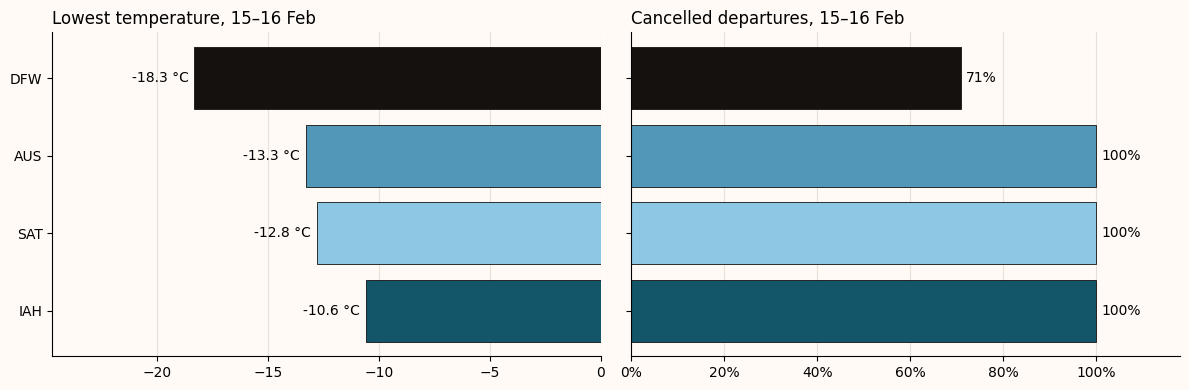

In [13]:
peak = ('2021-02-15', '2021-02-16')
a1 = pd.DataFrame({
    'min_temp': weather[weather['date'].between(*peak)].groupby('airport_code')['temp_c'].min(),
    'cancel_rate': dep[dep['flight_date'].between(*peak)].groupby('origin')['cancelled'].mean(),
    'flights': dep[dep['flight_date'].between(*peak)].groupby('origin').size(),
}).loc[AIRPORTS].sort_values('min_temp')
display(a1.round(2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
fig.patch.set_facecolor(BG)
y = list(range(len(a1)))
colors = [AIRPORT_COLORS[a] for a in a1.index]

style(ax1, 'x')
ax1.barh(y, a1['min_temp'], color=colors, edgecolor=INK, linewidth=0.6)
ax1.set_yticks(y, a1.index)
ax1.invert_yaxis()
ax1.set_xlim(a1['min_temp'].min() * 1.35, 0)
ax1.bar_label(ax1.containers[0], labels=[f'{v:.1f} °C' for v in a1['min_temp']], padding=4)
ax1.set_title('Lowest temperature, 15–16 Feb', loc='left')

style(ax2, 'x')
ax2.barh(y, a1['cancel_rate'], color=colors, edgecolor=INK, linewidth=0.6)
ax2.set_xlim(0, 1.18)
ax2.xaxis.set_major_formatter(PercentFormatter(1.0))
ax2.bar_label(ax2.containers[0], labels=[f'{v:.0%}' for v in a1['cancel_rate']], padding=4)
ax2.set_title('Cancelled departures, 15–16 Feb', loc='left')

plt.tight_layout()
save(fig, 'q4_coldest_airport_fewest_cancellations')
plt.show()

In [14]:
storm_raw = raw[raw['FlightDate'].between('2021-02-14', '2021-02-19') & raw['Origin'].isin(AIRPORTS)]
storm_cancelled = storm_raw[storm_raw['Cancelled'] == 1]

# cancellation reasons during the storm
display(pd.crosstab(storm_cancelled['Origin'], storm_cancelled['reason'], margins=True))

# DFW on the peak days: American Airlines vs. other operators
dfw_peak = raw[(raw['Origin'] == 'DFW') & raw['FlightDate'].between(*peak)].copy()
dfw_peak['carrier_group'] = np.where(dfw_peak['Reporting_Airline'] == 'AA', 'American', 'Other')
dfw_peak.groupby('carrier_group')['Cancelled'].agg(cancel_rate='mean', flights='size').round(2)

reason,Carrier,National Air System,Security,Weather,All
Origin,,,,,
AUS,8,0,4,386,398
DFW,43,1,0,2234,2278
IAH,4,17,0,992,1013
SAT,9,5,1,235,250
All,64,23,5,3847,3939


,cancel_rate,flights
carrier_group,,
American,0.64,480
Other,0.75,740


**Finding:** DFW was by far the coldest airport (down to −18.3 °C) but still operated **29 %** of its departures on 15–16 Feb (356 of 1,220) – while AUS, IAH and SAT cancelled **100 %**. IAH, the mildest airport (−10.6 °C), was shut down completely.

**Was it the weather?** Yes: 98 % of the 3,939 departures cancelled during the storm were reported as weather-related by the airlines.

**Airline or airport?** At DFW, American Airlines (whose hub it is) cancelled 64 % of its departures on the peak days, other operators 75 % – many of them American's regional partners. But even these operators cancelled far fewer flights than at the other three airports (100 %). The difference between airports is much larger than between airlines within DFW, so the airport itself seems to matter more than one airline's decisions.

**Why IAH shut down:** temperature alone does not explain it – snow and ice mattered more (see Q3). News reports add: on 15 Feb IAH closed its airfield because crews could not keep the runways free of ice.

#### Anomaly 2 – Airlines reacted instead of cancelling in advance

We expected airlines to cancel flights ahead of the forecast storm. To check, we compared the hour when snow or ice started at each airport with the first hour in which at least half of the scheduled departures were cancelled (hours with fewer than 3 flights are ignored).

In [15]:
start_w, end_w = '2021-02-13 18:00', '2021-02-17'

w = weather[weather['timestamp'].between(start_w, end_w)]
first_precip = w[w['winter_precip']].groupby('airport_code')['timestamp'].min()

hourly = dep[dep['sched_dep_hour'].between(start_w, end_w)] \
    .groupby(['origin', 'sched_dep_hour'])['cancelled'] \
    .agg(rate='mean', flights='count').reset_index()
first_cancel = hourly[(hourly['rate'] >= 0.5) & (hourly['flights'] >= 3)] \
    .groupby('origin')['sched_dep_hour'].min()

a2 = pd.DataFrame({'start_of_snow_ice': first_precip,
                   'first_hour_50pct_cancelled': first_cancel})
a2['lag_h'] = (a2['first_hour_50pct_cancelled'] - a2['start_of_snow_ice']).dt.total_seconds() / 3600
a2.sort_values('start_of_snow_ice')

,start_of_snow_ice,first_hour_50pct_cancelled,lag_h
SAT,2021-02-13 20:00:00,2021-02-14 08:00:00,12.0
DFW,2021-02-14 00:00:00,2021-02-14 13:00:00,13.0
AUS,2021-02-14 01:00:00,2021-02-14 13:00:00,12.0
IAH,2021-02-14 18:00:00,2021-02-14 19:00:00,1.0


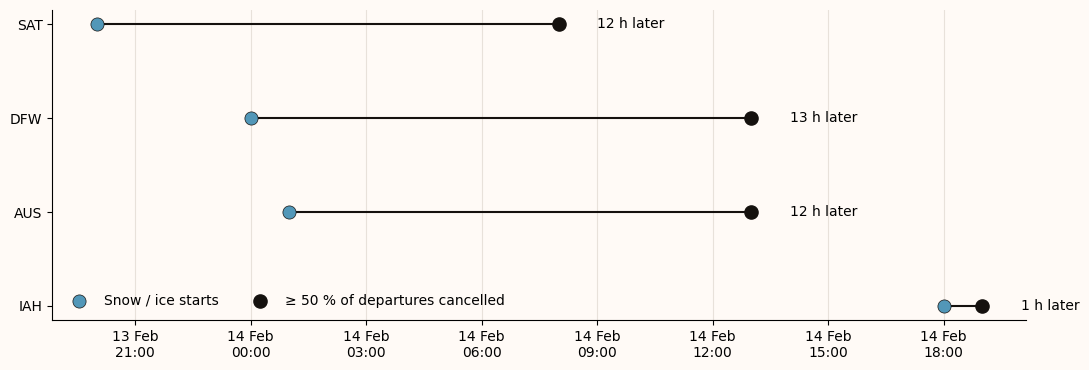

In [16]:
order = a2.sort_values('start_of_snow_ice').index
fig, ax = plt.subplots(figsize=(11, 3.8))
fig.patch.set_facecolor(BG)
style(ax, 'x')

for i, ap in enumerate(order):
    s, c, lag = a2.loc[ap, 'start_of_snow_ice'], a2.loc[ap, 'first_hour_50pct_cancelled'], a2.loc[ap, 'lag_h']
    ax.plot([s, c], [i, i], color=INK, linewidth=1.5, zorder=2)
    ax.scatter(s, i, s=90, color=BLUE, edgecolor=INK, linewidth=0.5, zorder=3,
               label='Snow / ice starts' if i == 0 else None)
    ax.scatter(c, i, s=90, color=INK, zorder=3,
               label='≥ 50 % of departures cancelled' if i == 0 else None)
    ax.text(c + pd.Timedelta(hours=1), i, f'{lag:.0f} h later', va='center', fontsize=10)

ax.set_yticks(range(len(order)), order)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b\n%H:%M'))
ax.legend(frameon=False, loc='lower left', ncol=2)
plt.tight_layout()
save(fig, 'q4_reaction_not_anticipation')
plt.show()

**Finding:** at SAT, DFW and AUS snow and ice started overnight, and morning departures still largely operated. Mass cancellations began **about 12 hours later** (SAT: 20:00 → 08:00, DFW: 00:00 → 13:00, AUS: 01:00 → 13:00). IAH, hit last, reacted within one hour.

**Why it matters:** although the storm was forecast days in advance, cancellations followed the weather rather than preceding it.

*Limitation:* the data shows whether a flight was cancelled, but not when the decision was made.

#### Anomaly 3 – A spike of diverted flights at DFW, unrelated to the storm

We expected diversions to rise during the storm. Instead we found a spike two weeks later.

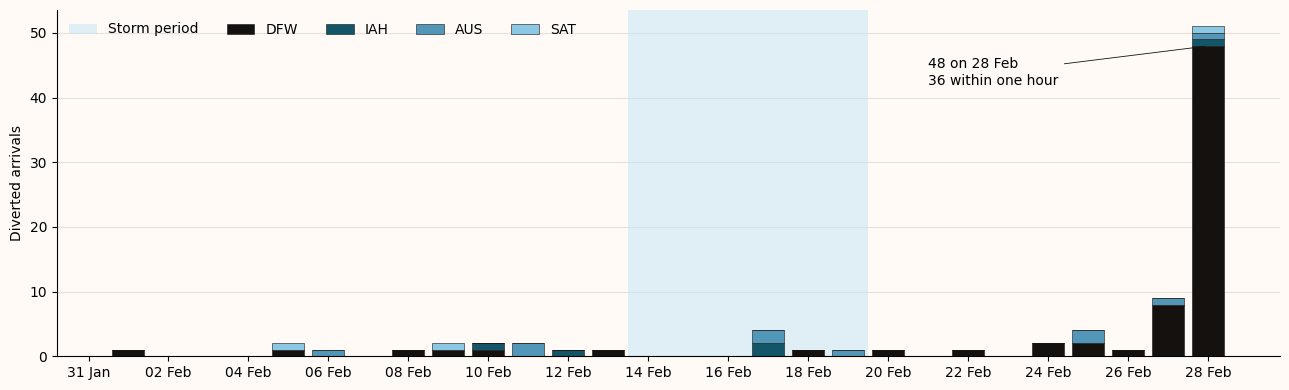

In [17]:
days = pd.date_range('2021-02-01', '2021-02-28')
div = arr.groupby(['flight_date', 'dest'])['diverted'].sum().unstack(fill_value=0) \
    .reindex(index=days, columns=AIRPORTS, fill_value=0)

fig, ax = plt.subplots(figsize=(13, 4))
fig.patch.set_facecolor(BG)
style(ax)
ax.axvspan(pd.Timestamp('2021-02-13 12:00'), pd.Timestamp('2021-02-19 12:00'),
           color=BLUE_LIGHT, alpha=0.5, lw=0, label='Storm period')
bottom = np.zeros(len(div))
for ap in AIRPORTS:
    ax.bar(div.index, div[ap], bottom=bottom, width=0.8, color=AIRPORT_COLORS[ap],
           edgecolor=INK, linewidth=0.4, label=ap)
    bottom += div[ap].values

ax.annotate('48 on 28 Feb\n36 within one hour', xy=(pd.Timestamp('2021-02-28'), 48),
            xytext=(pd.Timestamp('2021-02-21'), 42), fontsize=10,
            arrowprops=dict(arrowstyle='-', color=INK, lw=0.6))
ax.set_ylabel('Diverted arrivals')
ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
ax.legend(ncol=5, loc='upper left', frameon=False)
plt.tight_layout()
save(fig, 'q4_dfw_diversions')
plt.show()

In [18]:
d28 = raw[raw['FlightDate'] == '2021-02-28']

# 1. was it only DFW? (airports with the most diverted arrivals, US-wide)
print(d28.groupby('Dest')['Diverted'].sum().sort_values(ascending=False).head(5), '\n')
print('Dallas Love Field (DAL):', int(d28.loc[d28['Dest'] == 'DAL', 'Diverted'].sum()), '\n')

# 2. when and where did the diverted flights go?
div28 = d28[(d28['Dest'] == 'DFW') & (d28['Diverted'] == 1)].copy()
div28['sched_arr_hour'] = div28['CRSArrTime'] // 100
print(div28['sched_arr_hour'].value_counts().sort_index(), '\n')
print(div28['Div1Airport'].value_counts().head(5), '\n')

# 3. causes of arrival delays at DFW that day (minutes)
d28.loc[d28['Dest'] == 'DFW', ['NASDelay', 'LateAircraftDelay', 'WeatherDelay', 'CarrierDelay']].sum()

Dest
DFW    48.0
CLT    19.0
ASE     3.0
EWR     2.0
RFD     1.0
Name: Diverted, dtype: float64 

Dallas Love Field (DAL): 1 

sched_arr_hour
9      2
11    36
12     6
13     2
15     2
Name: count, dtype: int64 

Div1Airport
AUS    11
IAH    10
OKC     9
SAT     4
ABI     2
Name: count, dtype: int64 



NASDelay             16102.0
LateAircraftDelay     6921.0
WeatherDelay          3541.0
CarrierDelay          3157.0
dtype: float64

**Finding:** during the storm there were *fewer* diversions than usual – flights to closed airports were cancelled rather than sent into the air. But on **28 Feb, 48 flights bound for DFW were diverted** – more than at any other US airport that day, compared to 0–2 on a normal day. **36 of them were scheduled to arrive within a single hour (11:00)**; most landed at Austin, Houston and Oklahoma City instead.

**Why:** Dallas Love Field, 20 km away, was not affected, and more than half of the arrival delay minutes at DFW that day were caused by air traffic control restrictions (National Air System). So air traffic control briefly limited landings at DFW. The exact weather cause is not visible in our data: the airport station reports only light rain at that time. Possible explanations are low clouds or poor visibility (fog in the early morning) or storms on the approach ahead of a cold front that passed around midday. A separate event after Uri – a reminder that not every irregularity in the data is linked to the storm we chose.

### Summary Q4
Yes, the data shows unexpected patterns:
- the coldest airport, DFW, cancelled the fewest flights – and the difference between airports was much larger than between airlines;
- airlines reacted to snow and ice about 12 hours after they started instead of cancelling in advance;
- a spike of diversions at DFW on 28 Feb – caused by a short air traffic control restriction – had nothing to do with Uri.